## Particle Filter Design and Implementation

#### Assumptions
- State 
    - Starting with 1-D localization
- Measurements
    - Captured section of airport runway 
    - Clipped directly from the satellite image
    - Come from same image (eventually from ground image)
- Motion 
    - start with forward propagating motion from a random initial state
    - Constant velocity motion (eventually from INS)
    - UAV stays on centerline, heading aligns with runway
- Weighting
    - 2D comparison between images 
    - Utilizing one of a few methods explored in the lsa_detection script
        - structure tensor, hist, orb
    - TODO: determine score or likelihood function

- Map assumptions 
    - Known image map endpoints for runway (in pixels)
    - Known strip width (in pixels)
    - Size of capture window
    - Ground sample distance (GSD) TODO (m/px)


#### State and Units
State: $s$  (pixels along the strip)


## Checklist
- [x] Setup sim - strip, window size $L$
    - [x] True path (initial $s$, velocity, drift)
    - [ ] Noisy capture 
- [x] Initialization 
    - [x] Uniform over whole runway
    - [x] Initial uav position 
- [x] Prediction: motion plus process noise (eventually INS)
- [ ] Measurement update: 
    - [x] Actual measurement (simulator side)
    - [x] Score (filter) (particle window to capture)
    - [x] Convert to a likelihood
- [x] Resampling
- [ ] State Estimate: ??Weighted mean or highest weight mode??
- [ ] Eval:
    - [ ] Error over time 
    - [ ] $N_\text{eff}$: effective sample size: how many particles are really contributing, given spread of weight
    - [ ] Convergence time
    - [ ] Eval over repeated markings

#### Bayes update (per particle)
$$p(s_i \mid z) = \frac{p(z \mid s_i)\, p(s_i)}{p(z)}, \qquad p(z) = \sum_j p(z \mid s_j)\, p(s_j)$$

### Version 1
#### Score: mean squared error
$$\text{MSE}_i = \frac{1}{M}\sum_{\text{px}} \big(W(s_i) - z\big)^2$$

#### Likelihood
$$p(z \mid s_i) \propto \exp\left(-\frac{\text{MSE}_i}{2\sigma_z^2}\right), \qquad \ell_i = \log p(z \mid s_i) = -\frac{\text{MSE}_i}{2\sigma_z^2}$$

### Version 2
#### Preprocess: structure tensor (per pixel)
$$J = G_\sigma * \begin{bmatrix} g_x^2 & g_x g_y \\ g_x g_y & g_y^2 \end{bmatrix}, \qquad \hat{J} = \frac{J}{\text{tr}(J)}$$

$$\theta = \tfrac{1}{2}\,\text{atan2}\big(2\hat{J}_{xy},\; \hat{J}_{xx} - \hat{J}_{yy}\big), \qquad \hat{J} \leftarrow 0 \;\text{ if } |\theta| > \theta_{max}$$

#### Score: NCC
$$\text{NCC}_i = \frac{\tilde{\mathbf{z}} \cdot \tilde{\mathbf{w}}_i}{\|\tilde{\mathbf{z}}\|\,\|\tilde{\mathbf{w}}_i\|}$$

#### Likelihood
$$p(z \mid s_i) \propto \exp\left(-\frac{1 - \text{NCC}_i}{2\sigma_z^2}\right), \qquad \ell_i = -\frac{1 - \text{NCC}_i}{2\sigma_z^2}$$

- $\tilde{\mathbf{z}}$, $\tilde{\mathbf{w}}_i$: flattened $\hat{J}$ windows (3 channels), mean subtracted
- $1 - \text{NCC}$ is half the squared distance between the normalized windows, so this is a Gaussian on that distance

#### Terms
- $p(s_i)$: prior, how believable particle $i$ was before this measurement (its current weight $w_i$, after `predict`)
- $p(z \mid s_i)$: likelihood, how well particle $i$'s window matches the capture
- $p(z)$: normalizer, the sum of prior $\times$ likelihood over all particles, so the weights sum to 1
- $p(s_i \mid z)$: posterior, the new weight $w_i$
- If resampling every step, weights reset to $1/N$ and the update reduces to $p(s_i \mid z) \propto p(z \mid s_i)$. Here we resample only when $N_\text{eff}$ drops, so the $p(s_i)$ term is kept.
- Why $p(s_i)$ is just the current weight: `predict` moves particles with the motion model (bootstrap PF), so the general proposal correction cancels


In [1]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt

from pf_sim_1d import *
from map_utils import rectify_strip

# Autosave WORK
%load_ext autoreload
%autoreload 2
%autosave 180

Autosaving every 180 seconds


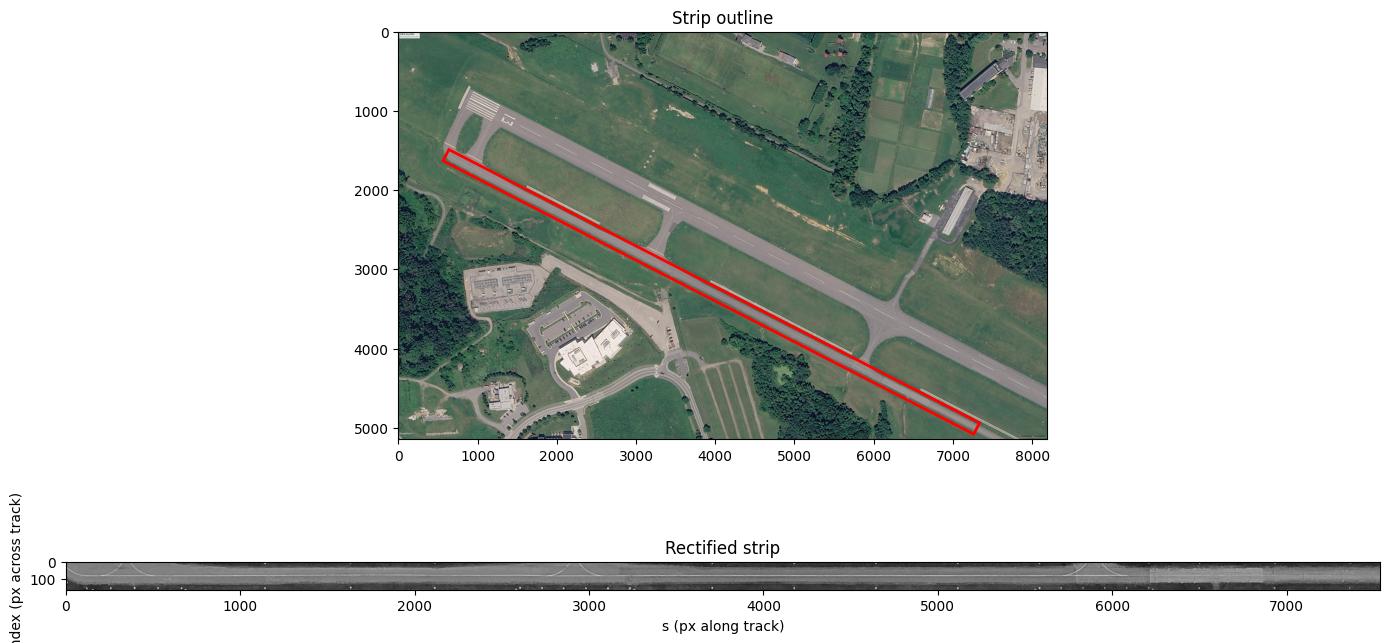

In [2]:
# Satellite imagery 
# Public google earth pro satellite imagery
# sat_ref = "../../datasets/KBCB_satellite/KBCB_partial.jpg" 
# sat_ref = "../../datasets/KBCB_satellite/KBCB_partial_LSA.png" 
# NEWER IMAGES - NOVEMBER 2026 
sat_ref = "../../datasets/KBCB_satellite/nov_2026/KBCB_half.jpg" 

sat_rgb = cv2.cvtColor(cv2.imread(sat_ref), cv2.COLOR_BGR2RGB) # Convert color and read
sat_gray = cv2.cvtColor(cv2.imread(sat_ref), cv2.COLOR_BGR2GRAY)

# Known Satellite lane enpoints 
# p0, p1 = (200, 444), (1850, 1312) # Partial LSA image 
# p0, p1 = (1000, 909), (8000, 4523) # Half - nov 2026 image, RUNWAY 
p0, p1 = (600, 1558), (7300, 5009) # Half - nov 2026 image, TAXIWAY

# known runway halfwdith 
# half_w = 40 # Partial LSA image 
# half_w = 125 # Half - nov 2026 image, RUNWAY 
half_w = 80 # Half - nov 2026 image, TAXIWAY (actual half waidth 45) #80 # 100
# half_w = 45 # Half - nov 2026 image, TAXIWAY (actual half waidth 45) 

# Get runway strip and pointer vectors
strip, u, n = rectify_strip(sat_gray, p0, p1, half_w)

# View im
corners = np.array([p0 + half_w*n, p1 + half_w*n, p1 - half_w*n, p0 - half_w*n])
fig, axs = plt.subplots(2, 1, figsize=(14, 8))
axs[0].imshow(sat_rgb)
axs[0].add_patch(plt.Polygon(corners, fill=False, ec='r', lw=2))
axs[0].set_title("Strip outline")
axs[1].imshow(strip, cmap='gray')#, aspect='auto')
axs[1].set_title("Rectified strip")
axs[1].set_xlabel("s (px along track)")
axs[1].set_ylabel("t index (px across track)")
plt.tight_layout()


## Scene setup and particle filter initialization 

In [3]:
# GROUND TRUTH DATA - TRAJECTORY

# Generate true trajectory 
random_seed = 17
rng_sim = np.random.default_rng(random_seed)
W = strip.shape[1]
s0 = int(rng_sim.integers(W // 3, 2 * W // 3)) # Random but in middle third of strip
# s0 = int(rng_sim.integers(W // 5, W // 4))
s0 = 3000
# s0 = 3200 # 3200 # 3500

# True Trajectory (replace with INS readings)
v = -50 # Velocity (px/s)
dt = 1 # time step (s)
K = 20 # Steps 
heading = int(np.sign(v))

sigma_meas = 0 # Actual noise added to the capture (simulator side)

print(f'Initial position (px): {s0} \nVelocity: {v} px/s \nTime step: {dt} s \n{K} steps \nHeading: {'W --> E' if heading == 1 else 'E --> W'}')


s_true = true_path(s0, v, dt, K)

Initial position (px): 3000 
Velocity: -50 px/s 
Time step: 1 s 
20 steps 
Heading: E --> W


In [4]:
# Particle filter Initialization 

# Preprocess satellite image 
J_strip = st_preprocess(strip)                      # once

# Params
L = 100 # Window length 
n_particles = 1000 # Number of particles
sigma_s = 2 # pixel std for motion prediction

sigma_z = 10 # noise level the filter assumes when scoring matches (FOR ORIGINAL UPDATE STEP)
sigma_z_st = .4 # likelihood std on the 1-NCC scale (FOR STRUCTURE TENSOR UPDATE)



pf = ParticleFilter1D(strip, L, n_particles, sigma_s, random_seed, heading=heading)

### Filter Implementation 

- Initial example of particle disribution 

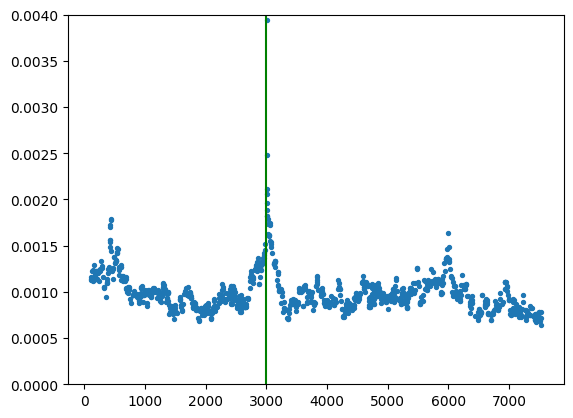

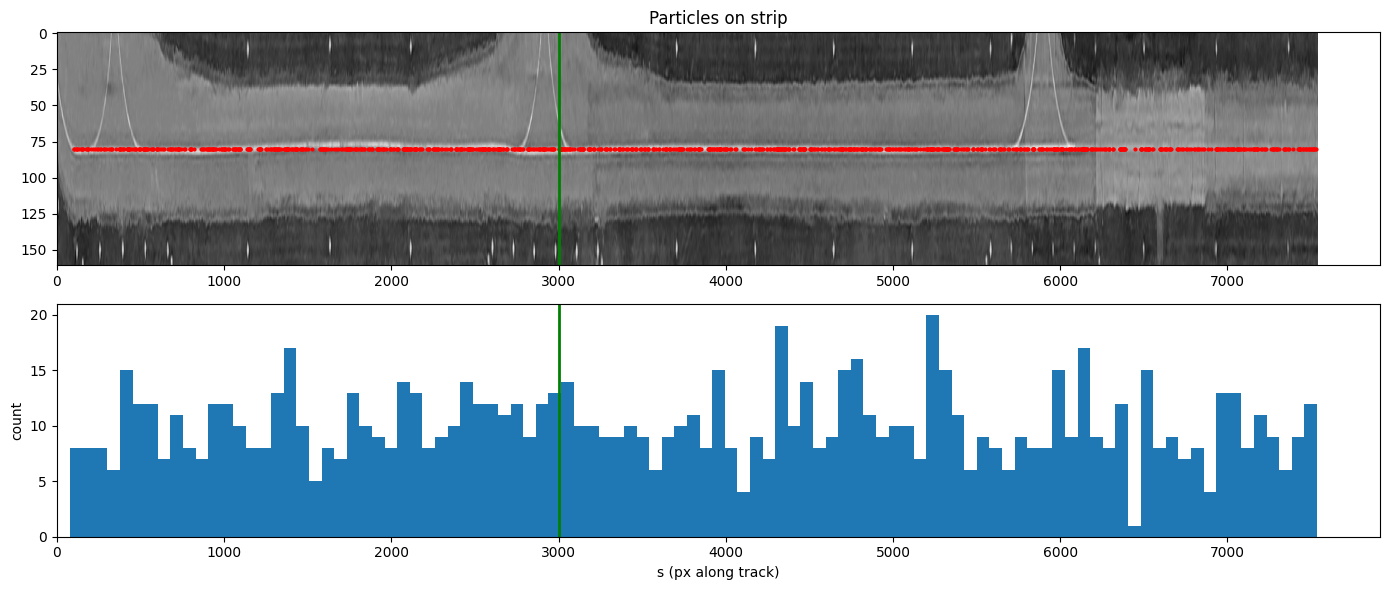

In [5]:
# Initialize particles and view

pf.init_uniform()
z = capture(strip, s_true[0], L, heading)
# pf.update(z, sigma_z)
pf.update_st(st_preprocess(z), J_strip, sigma_z_st)
plt.scatter(pf.particles, pf.weights, s=8)
plt.ylim(0, 0.004)

plt.axvline(s_true[0], c='g')
plot_curr_particles(strip, pf.particles, s_true[0])

## FULL Timestep loop (slow version)

Timestep: 0


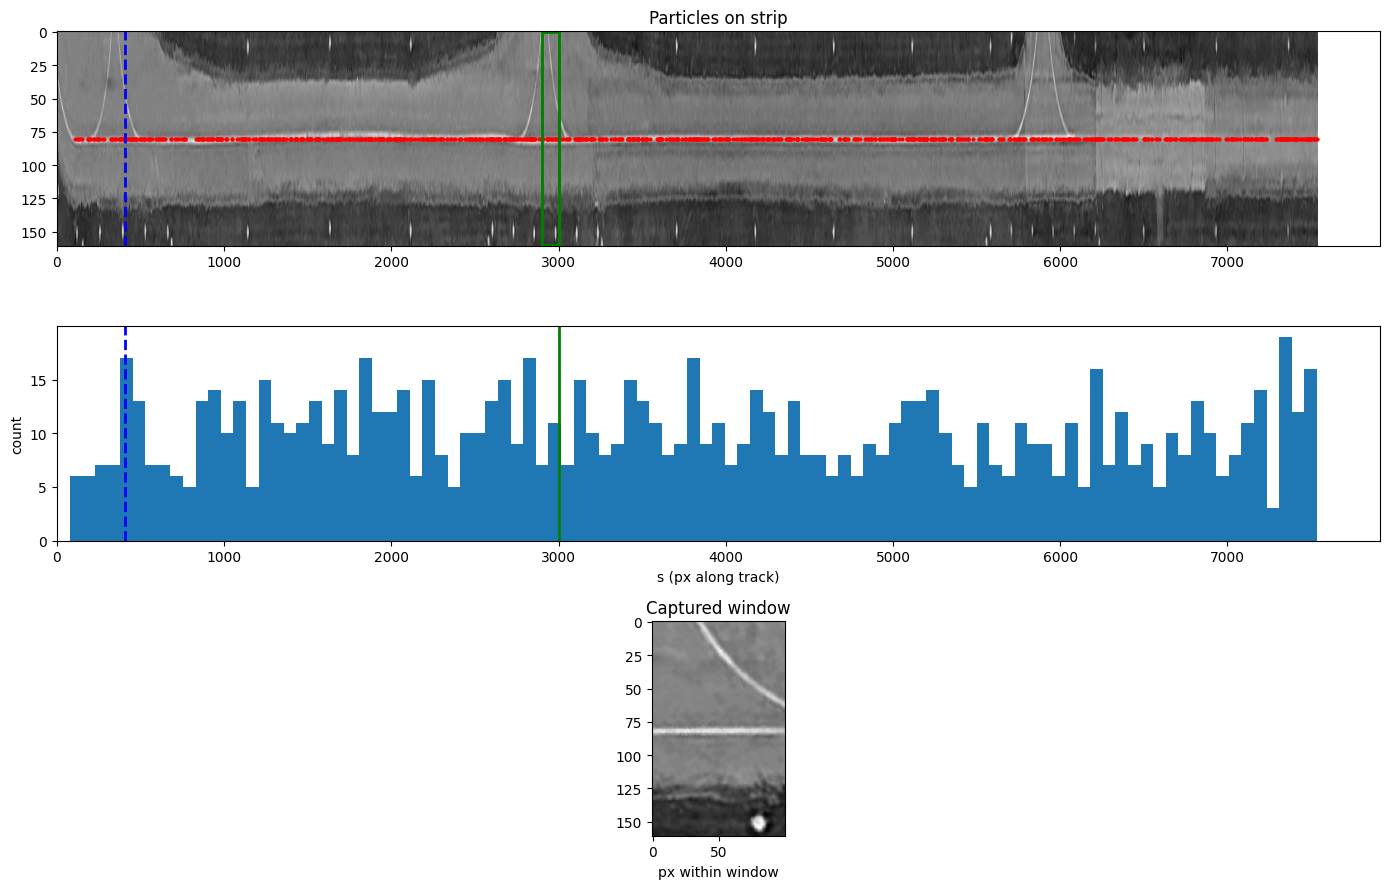

Timestep: 1


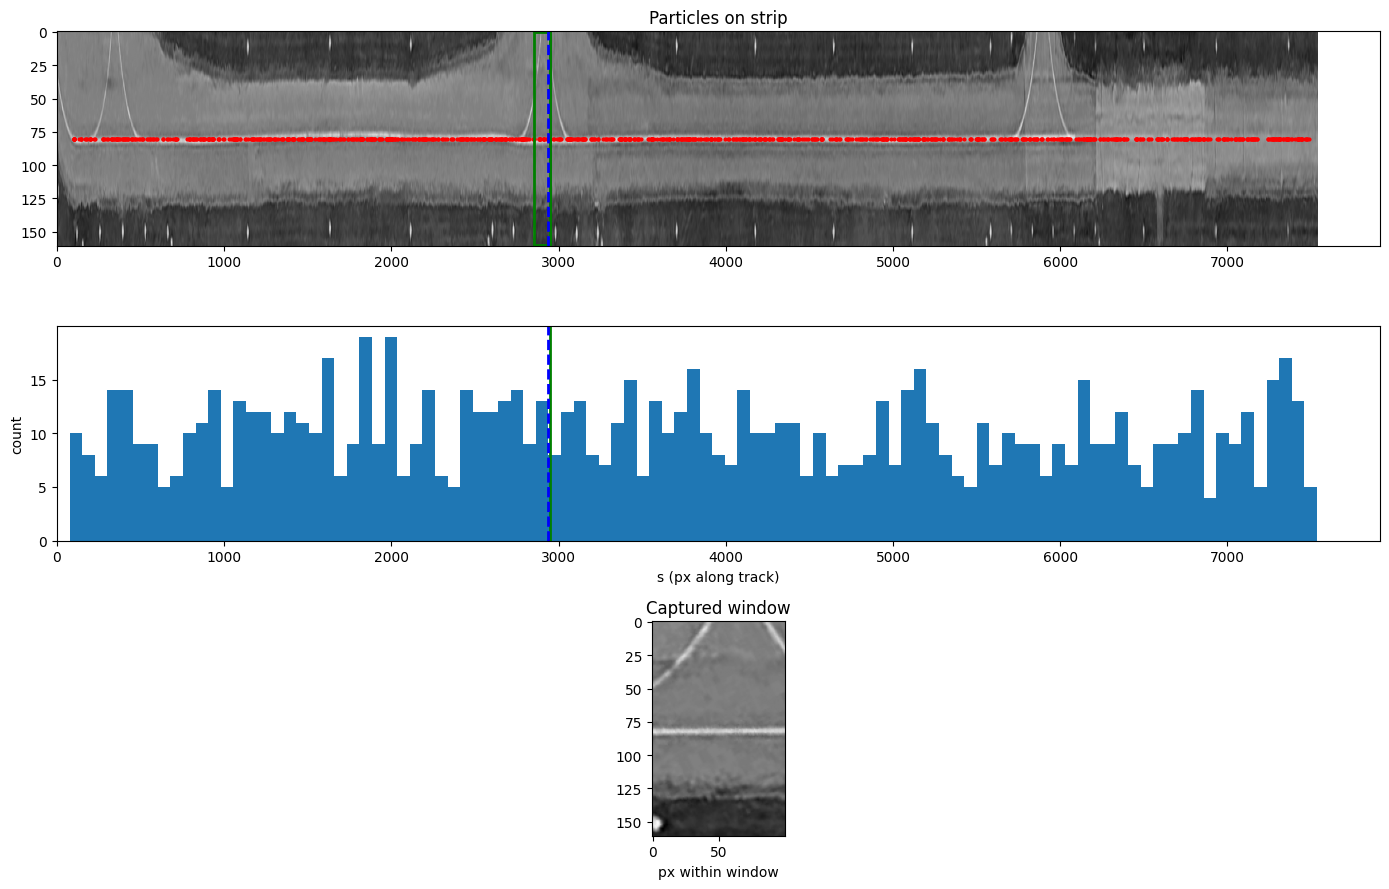

Timestep: 2


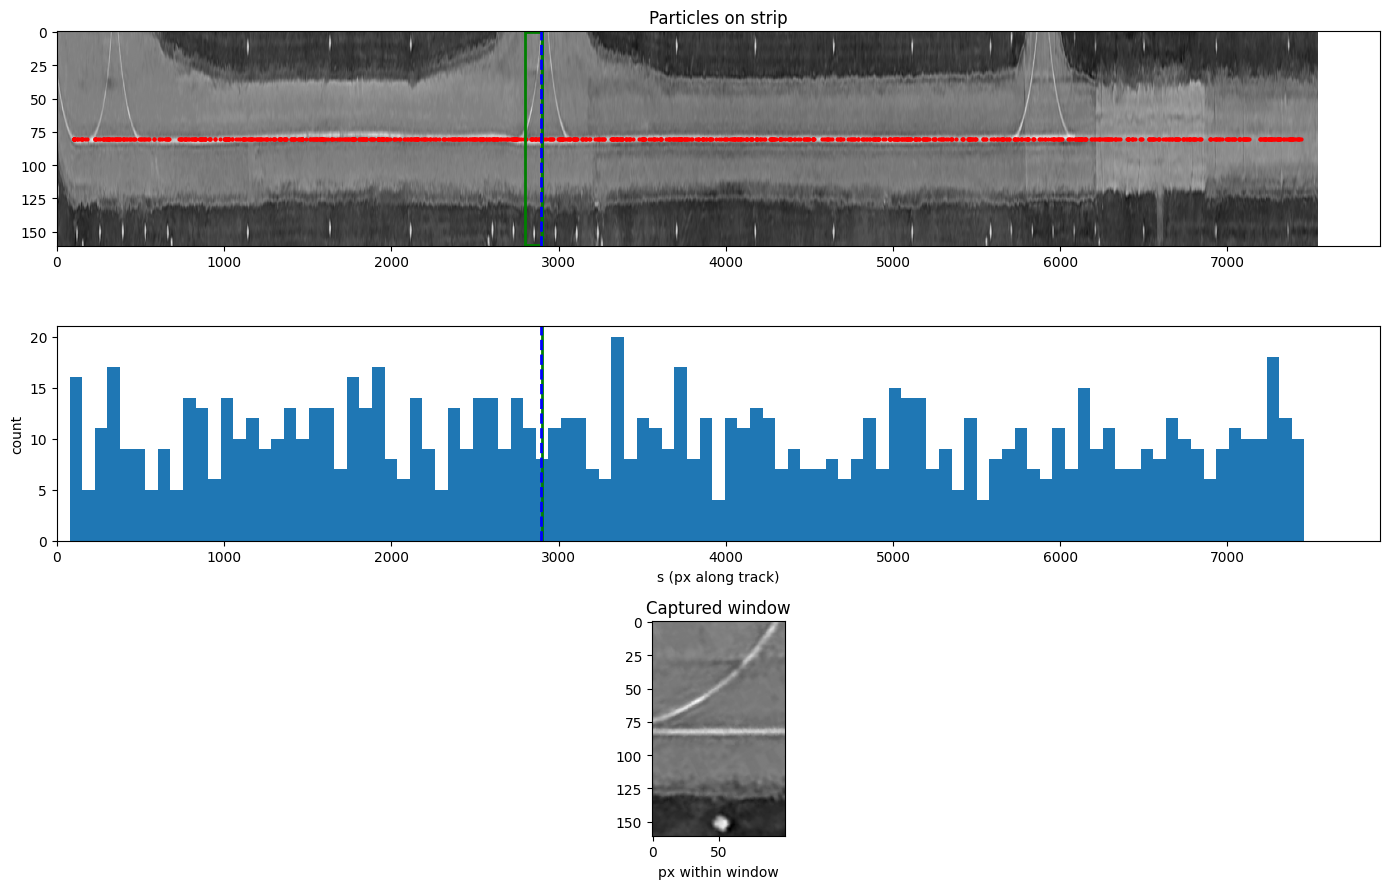

Timestep: 3
RESAMPLE


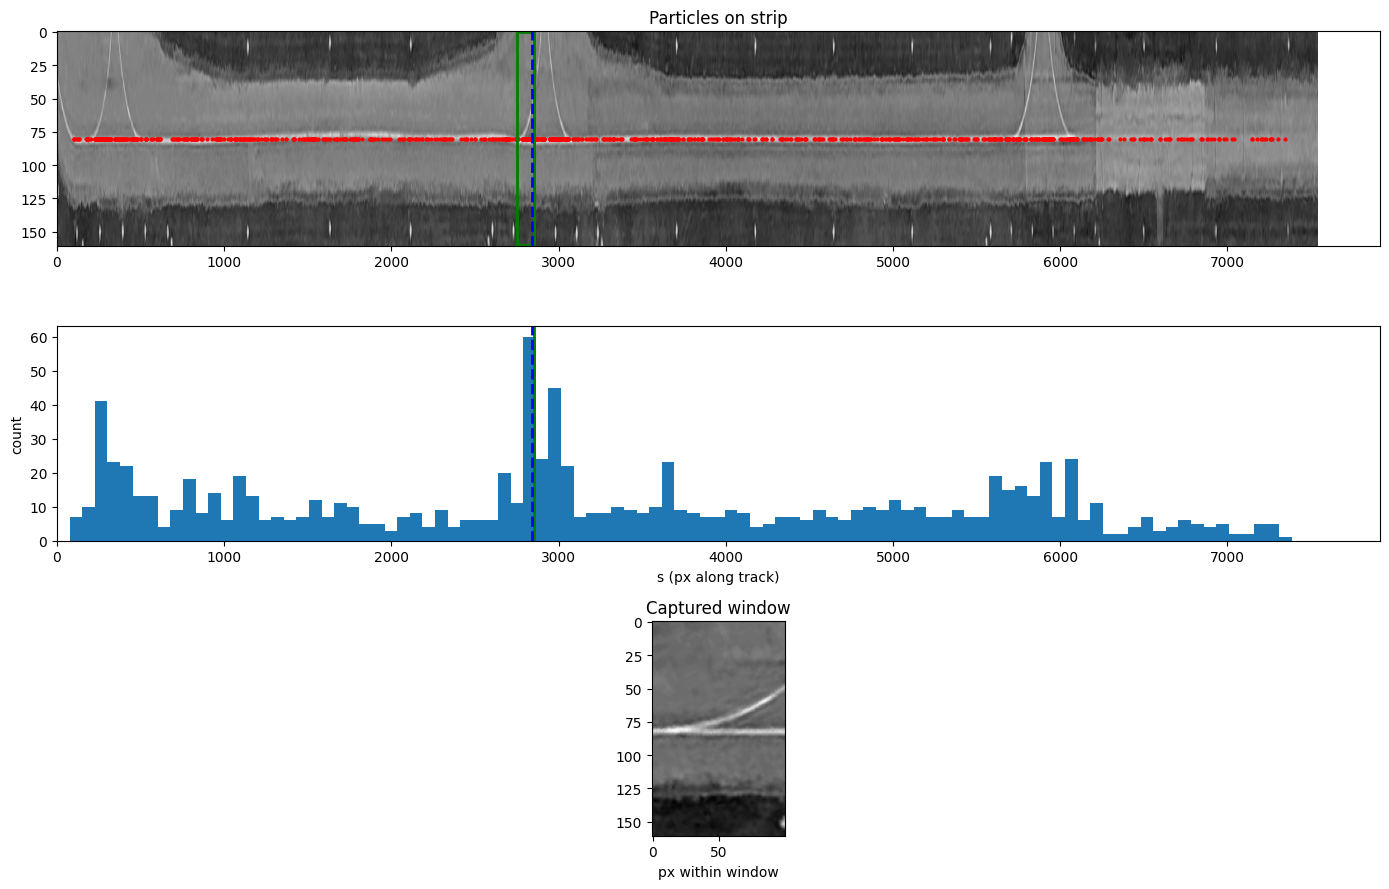

Timestep: 4


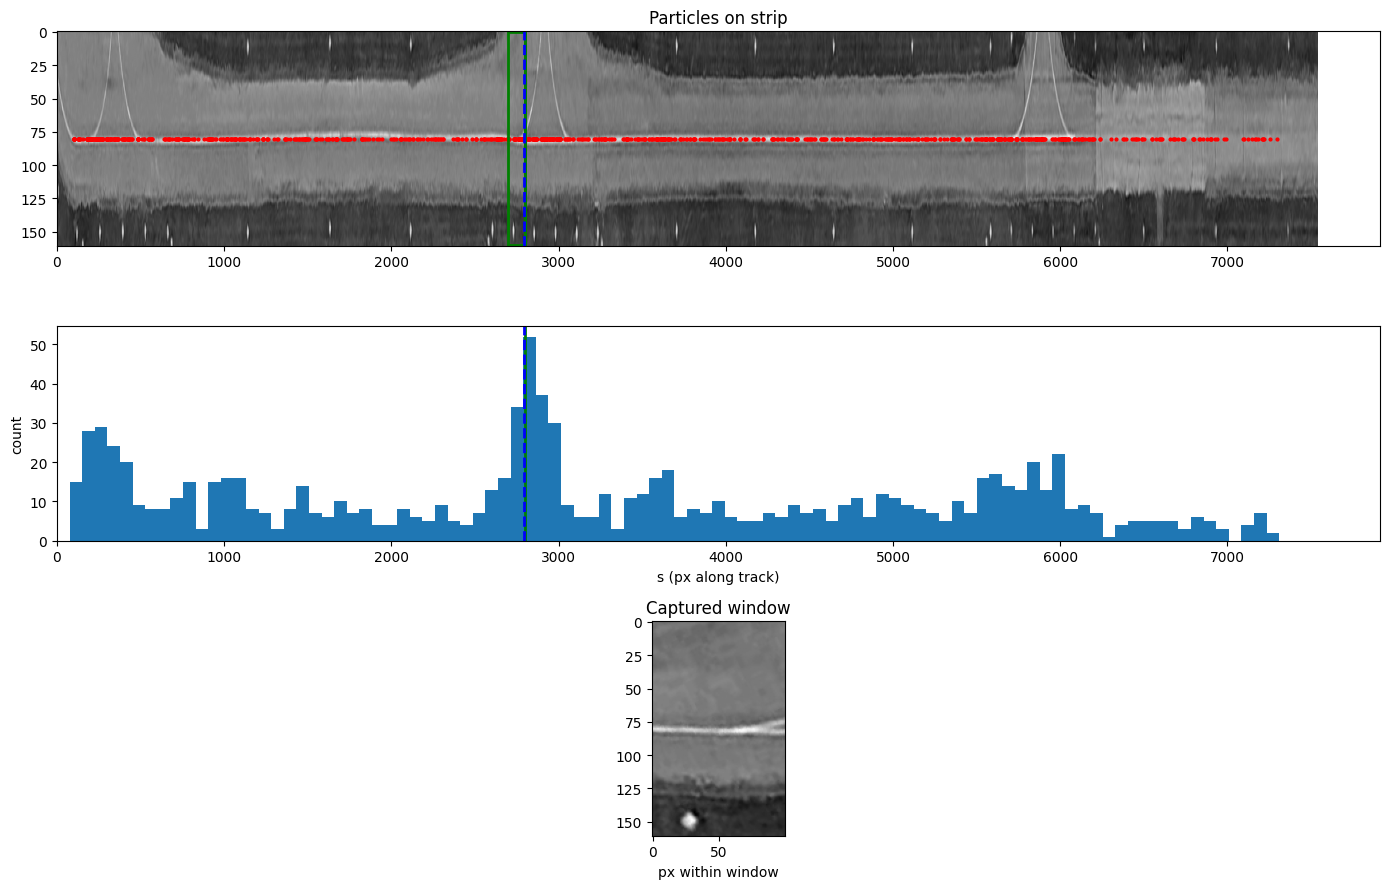

Timestep: 5


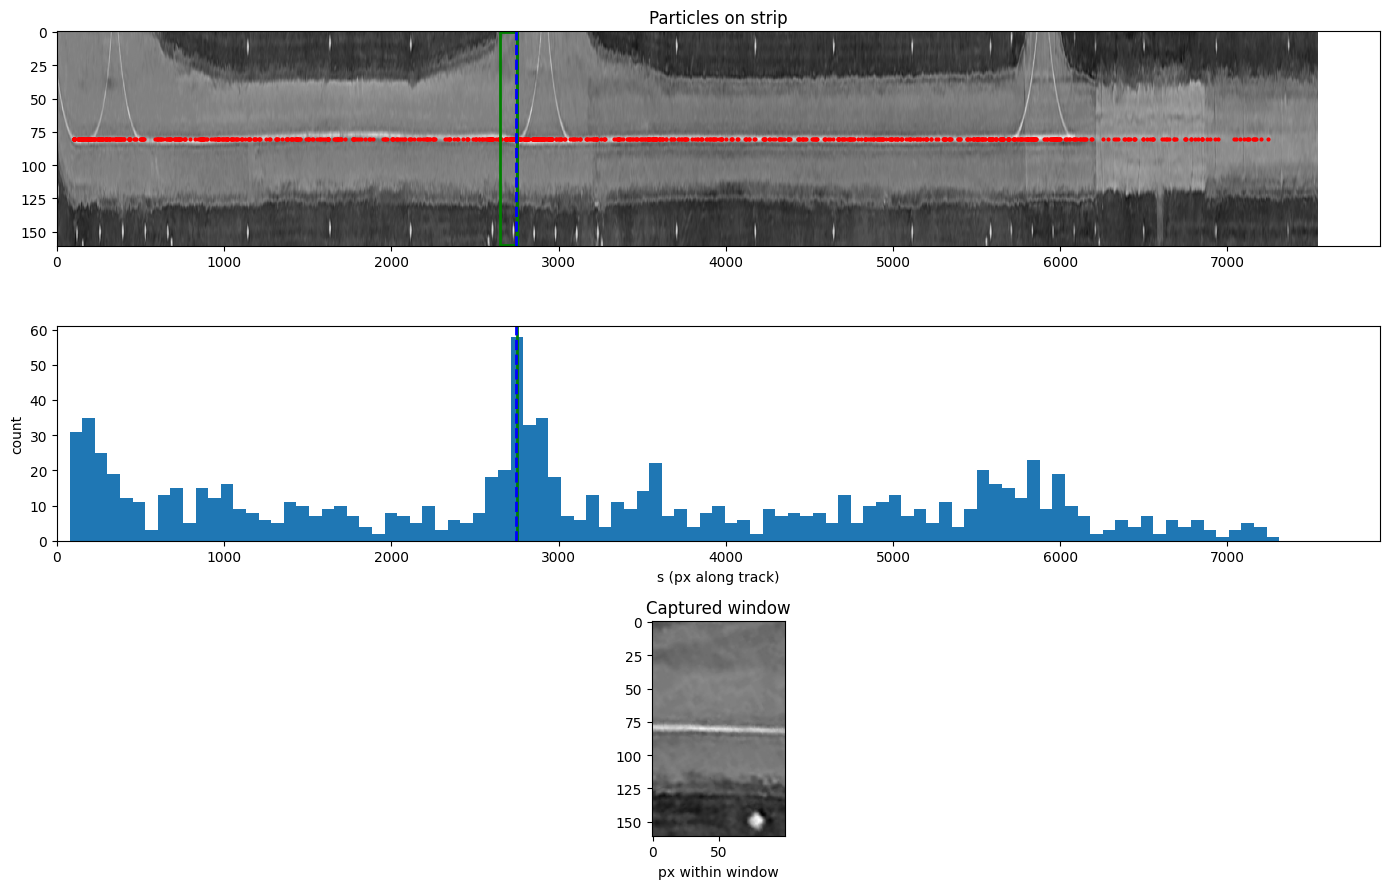

Timestep: 6
RESAMPLE


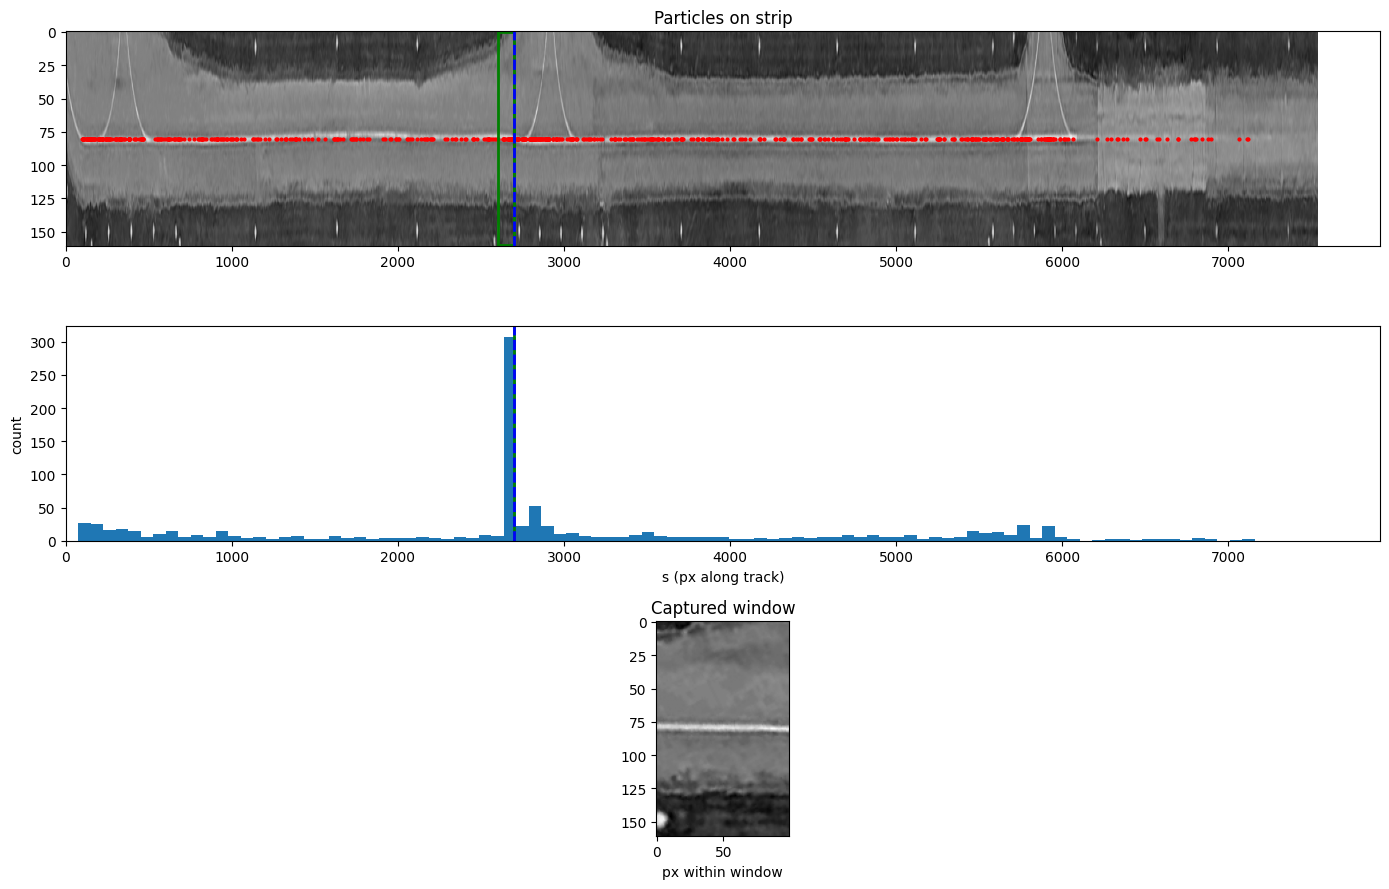

Timestep: 7
RESAMPLE


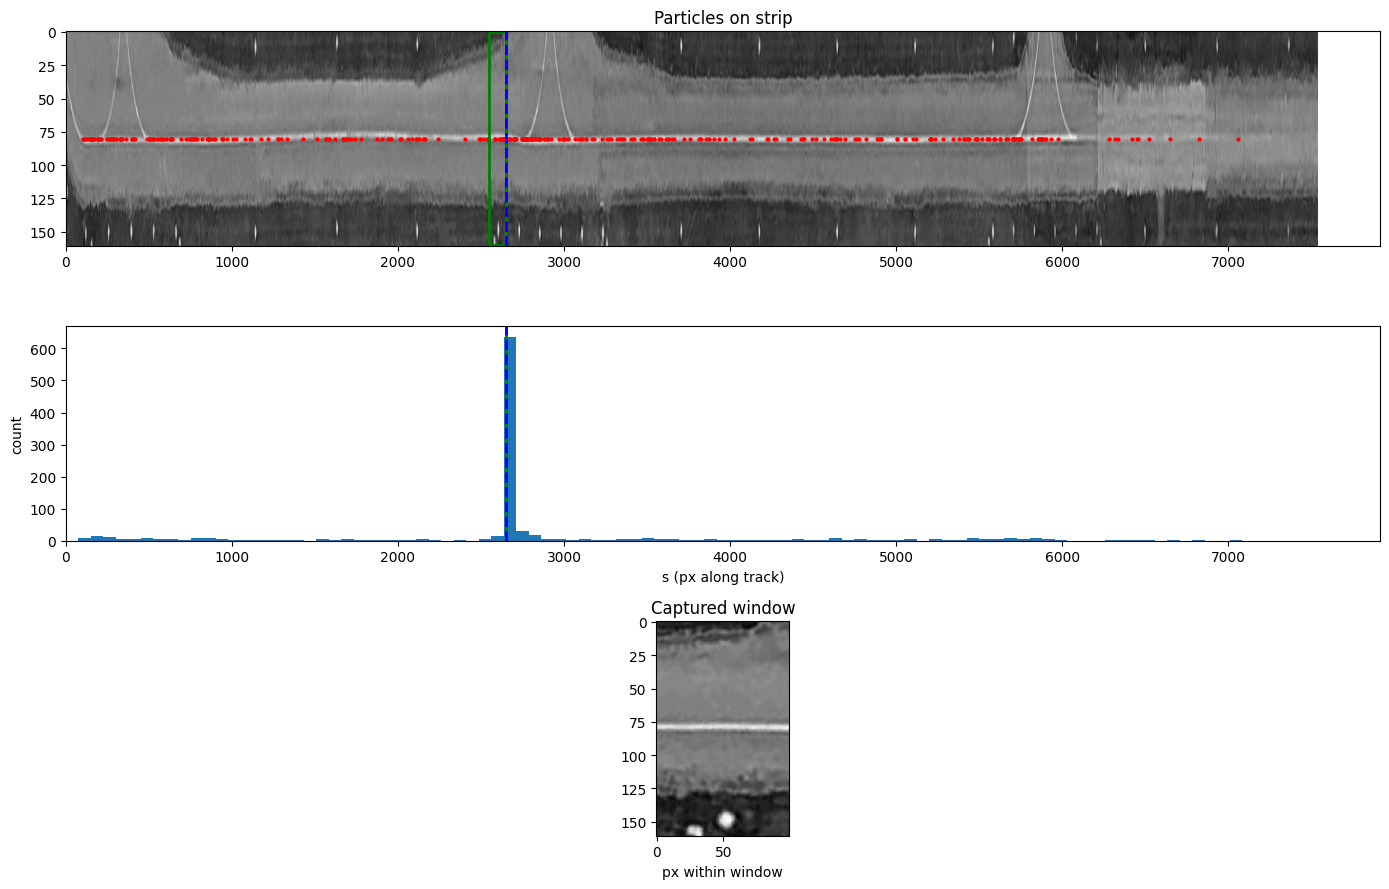

Timestep: 8


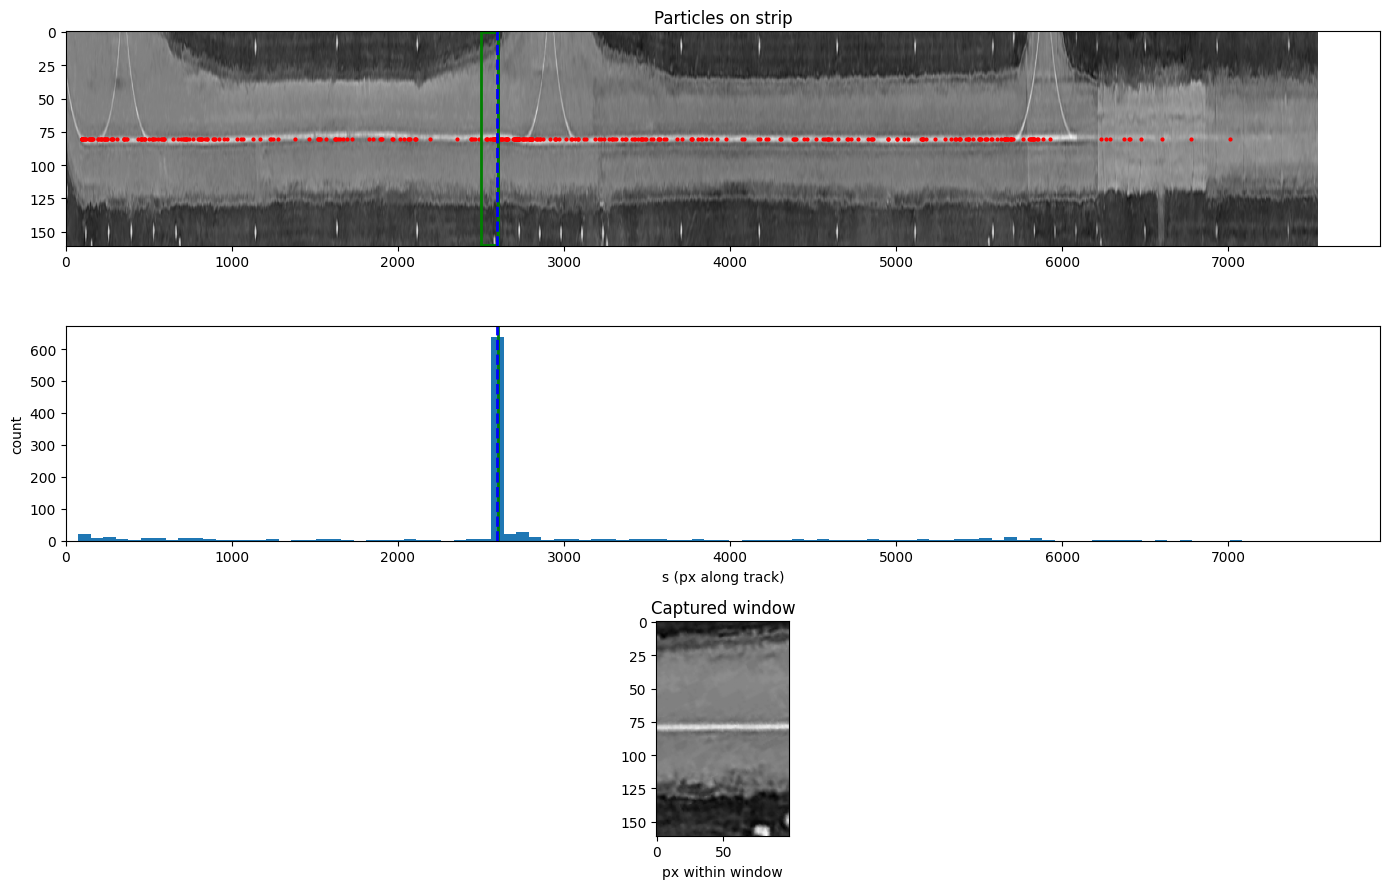

Timestep: 9
RESAMPLE


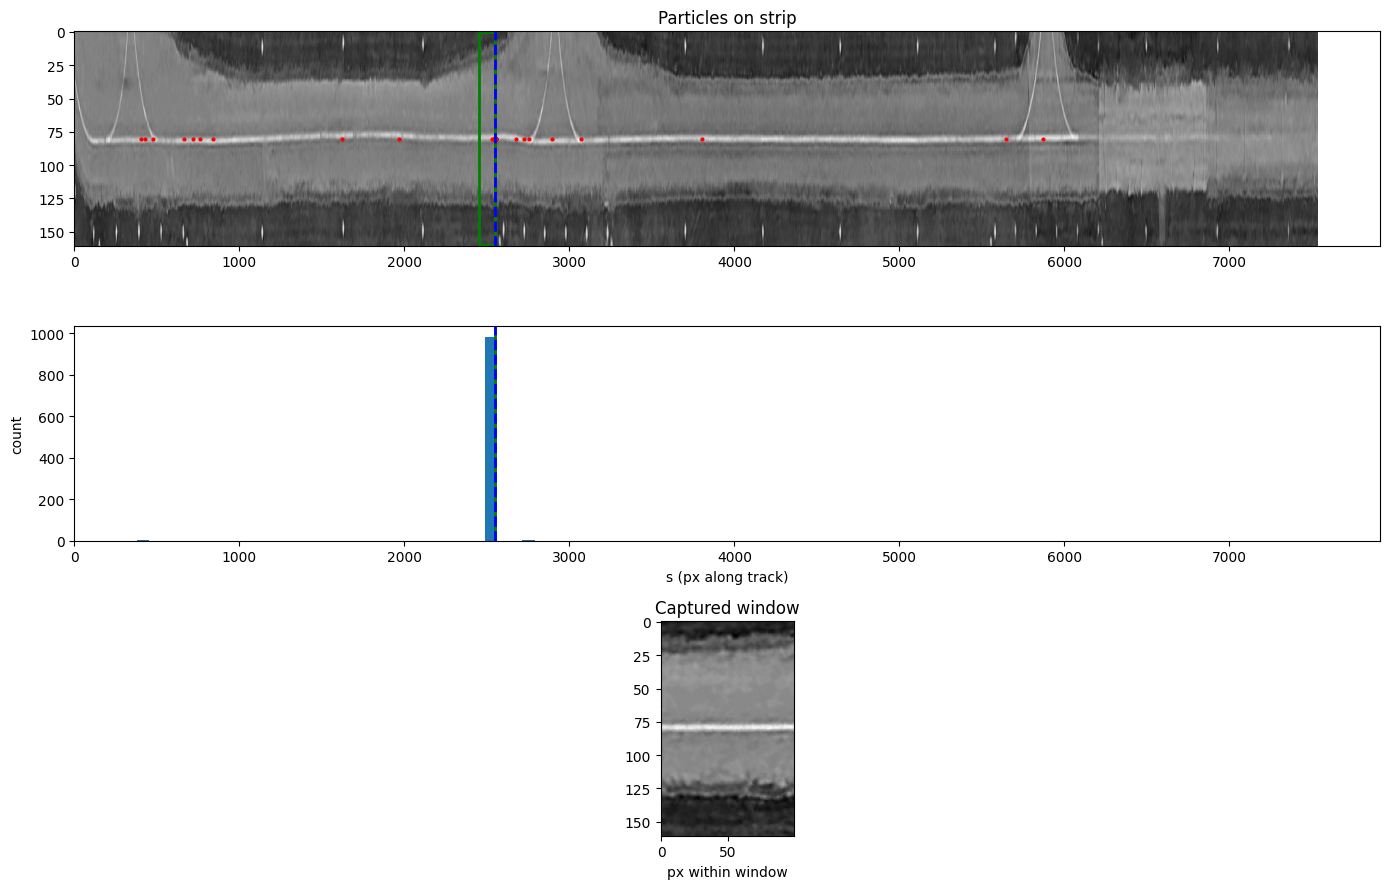

Timestep: 10


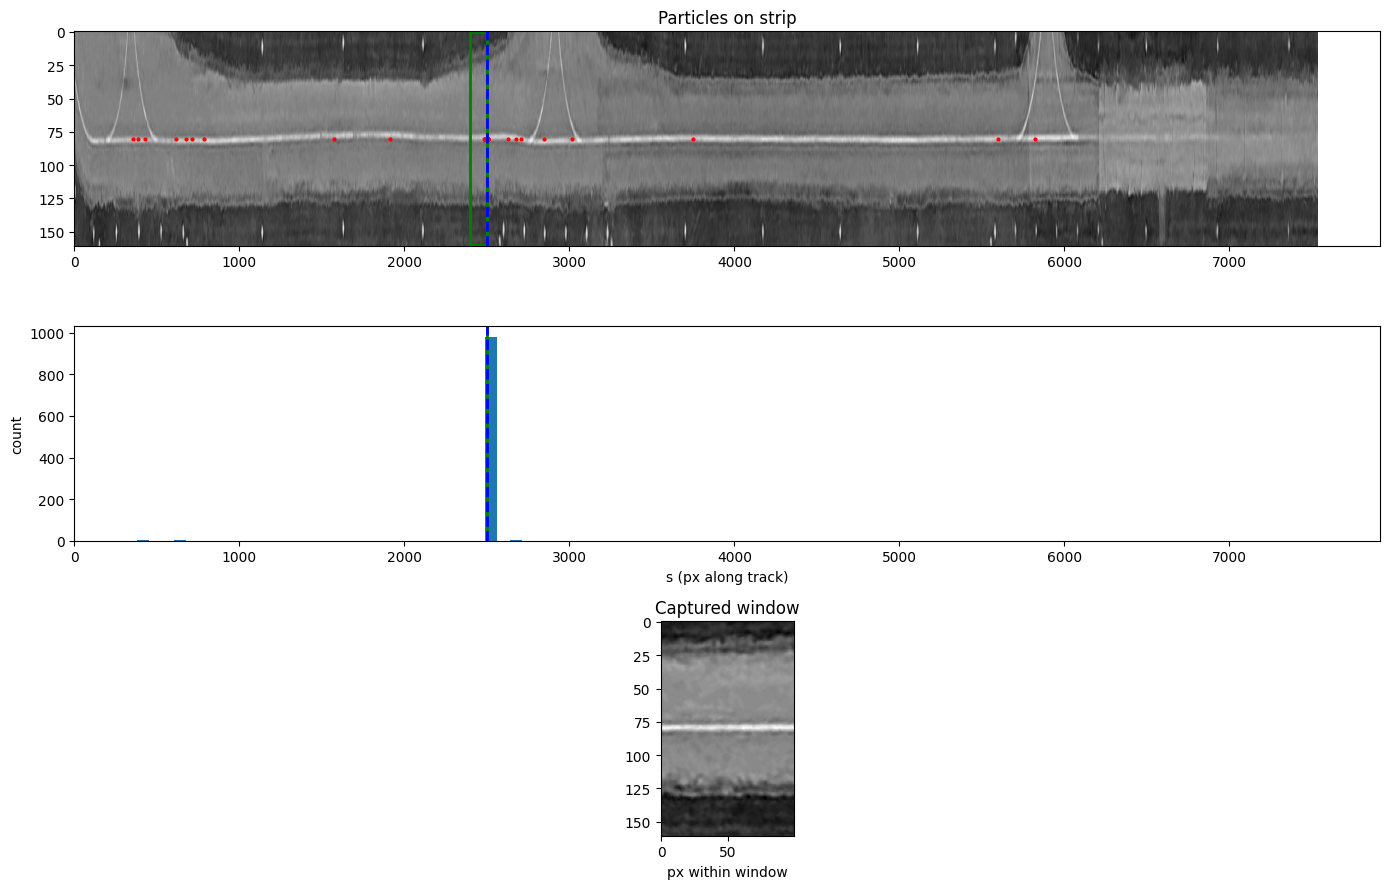

Timestep: 11


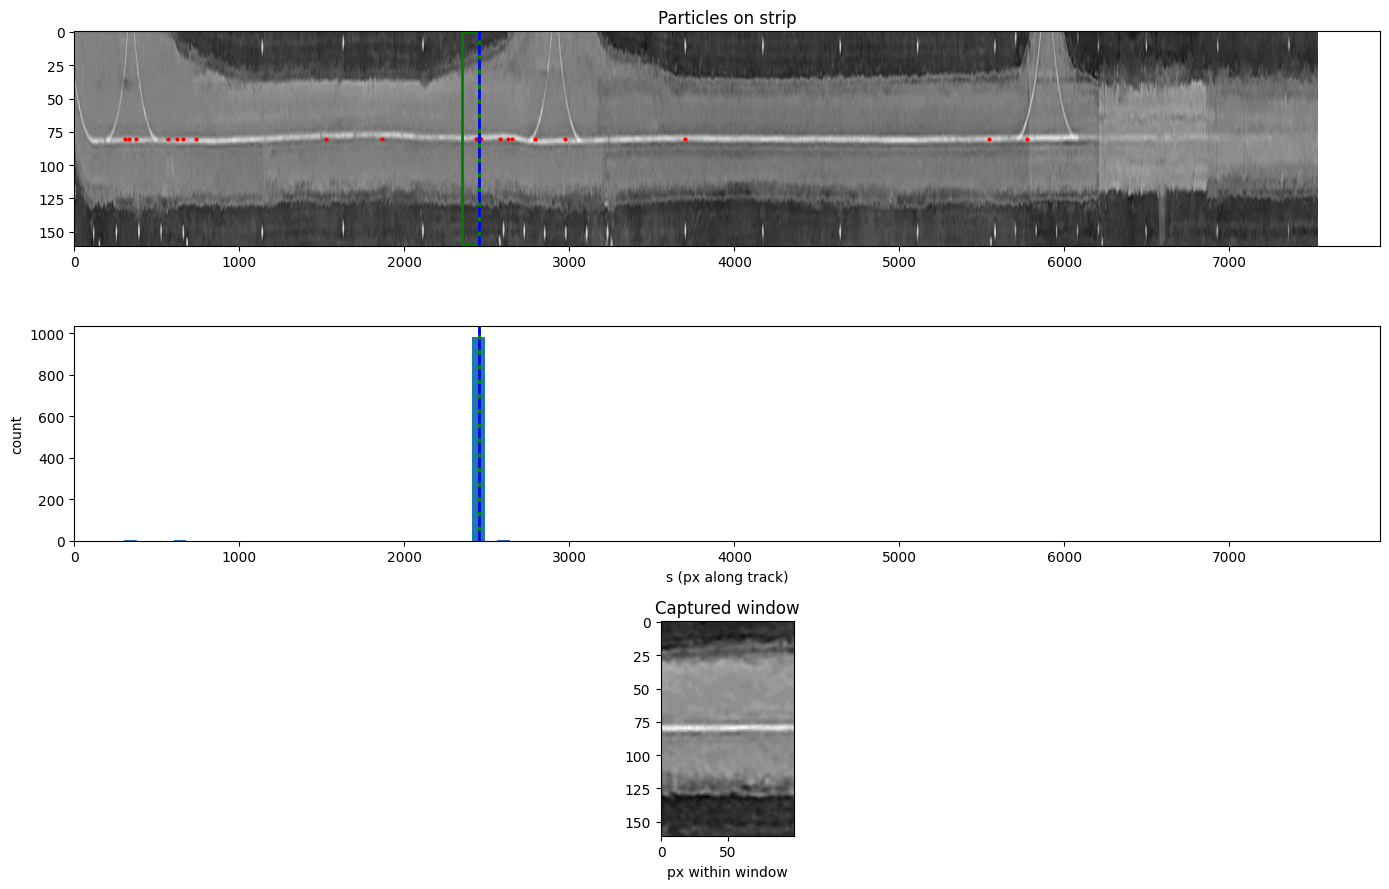

Timestep: 12
RESAMPLE


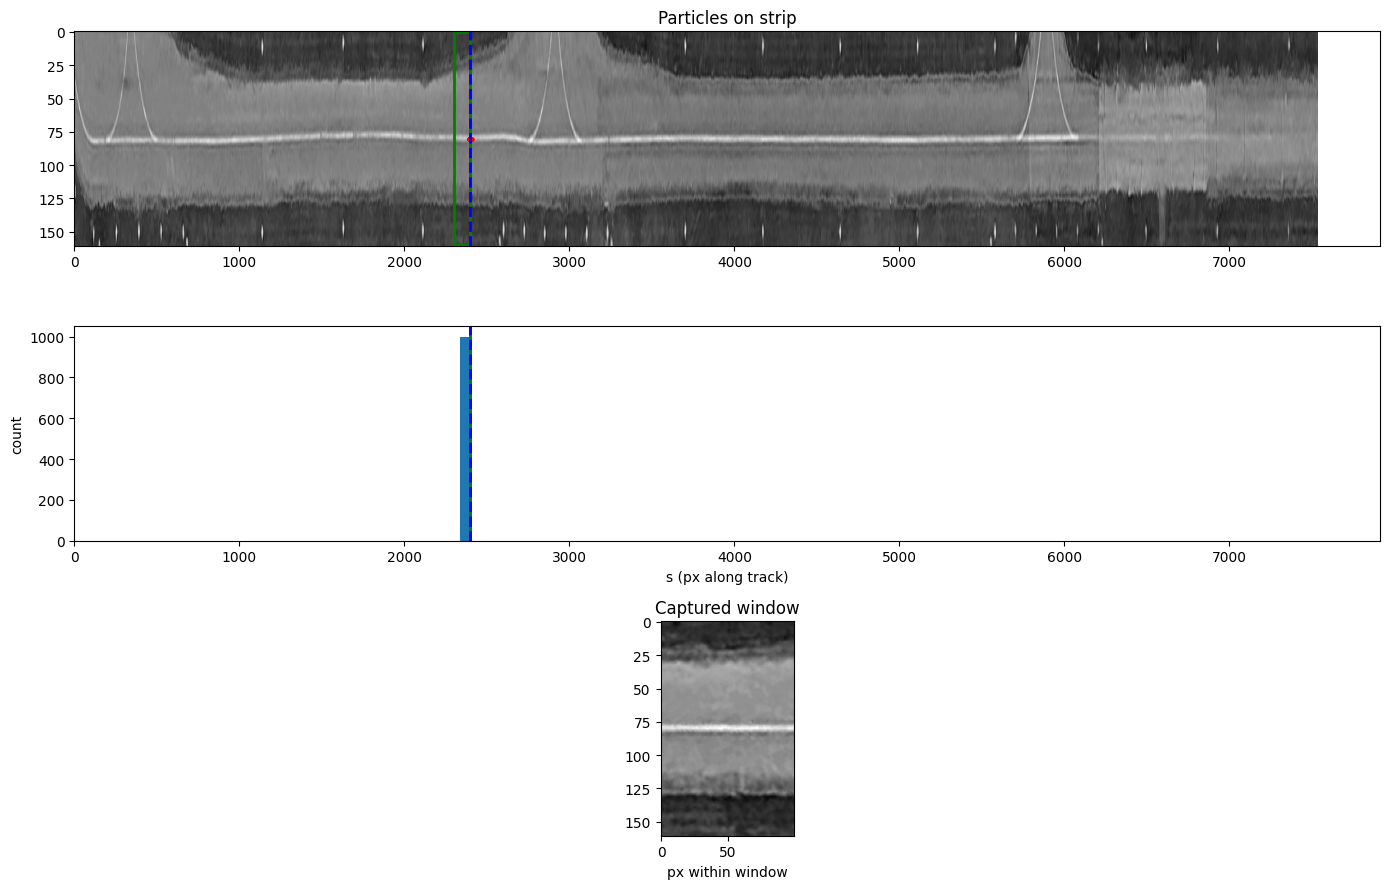

Timestep: 13


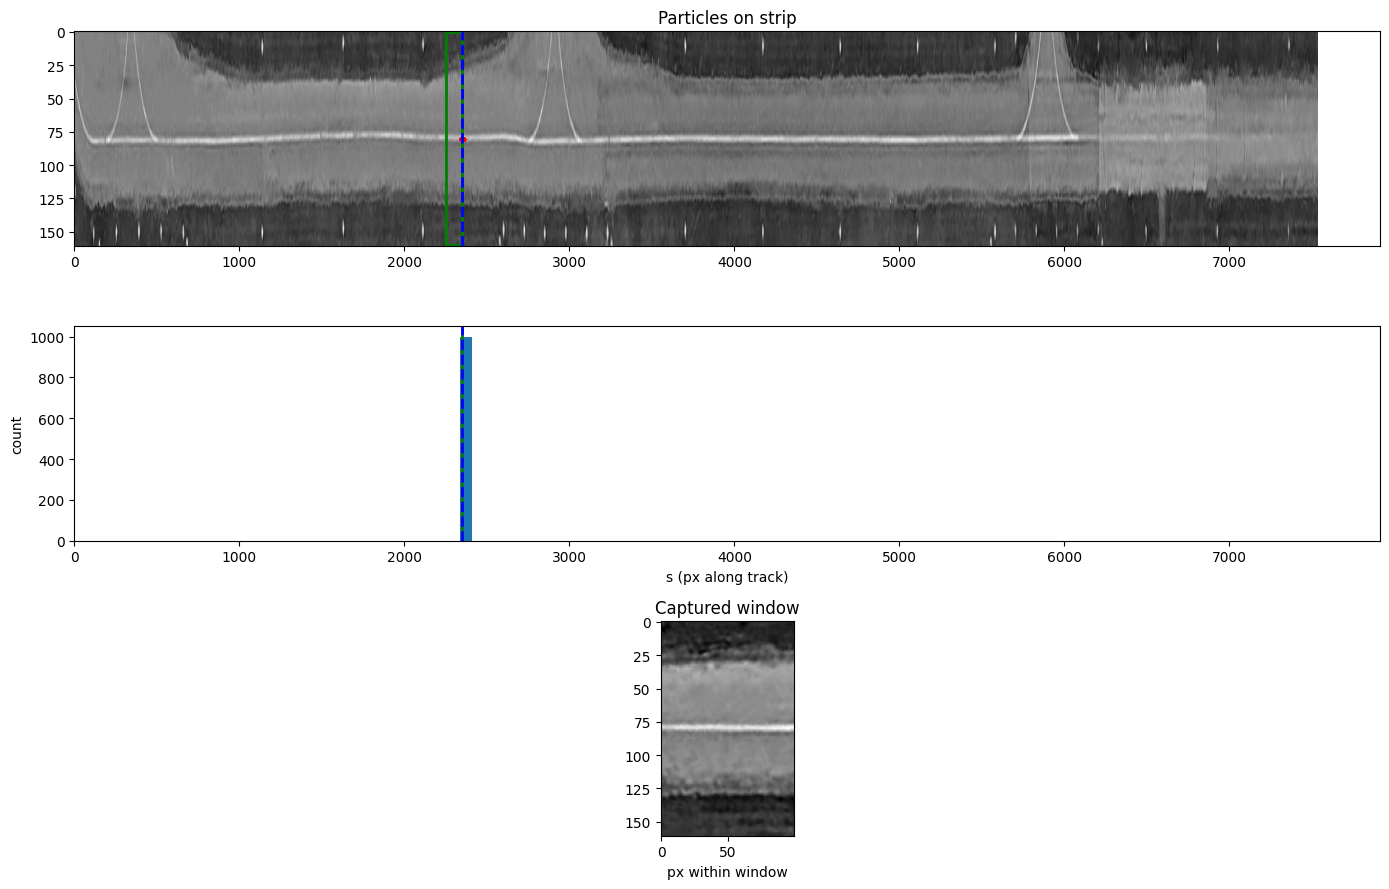

Timestep: 14


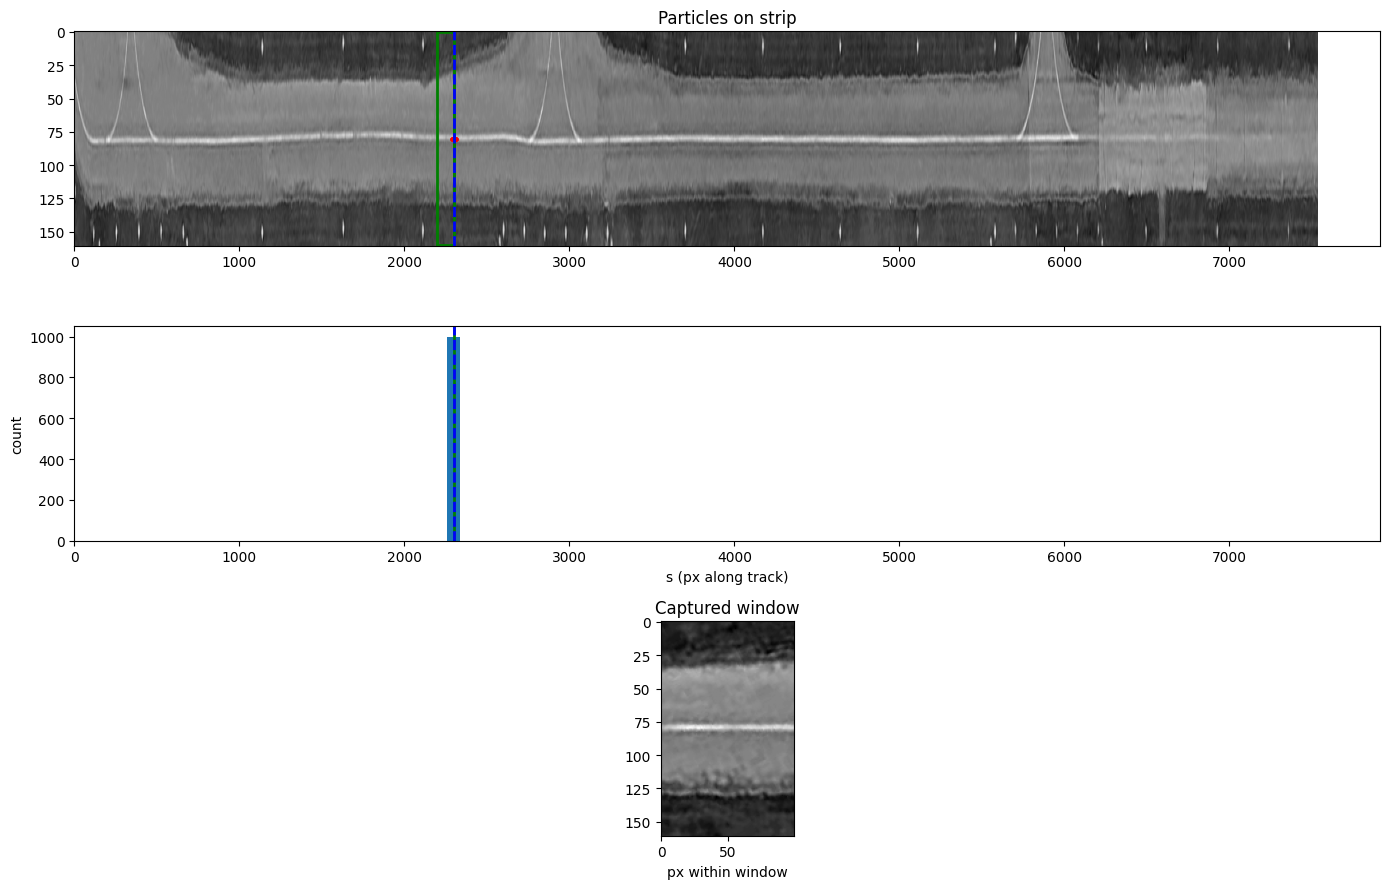

Timestep: 15
RESAMPLE


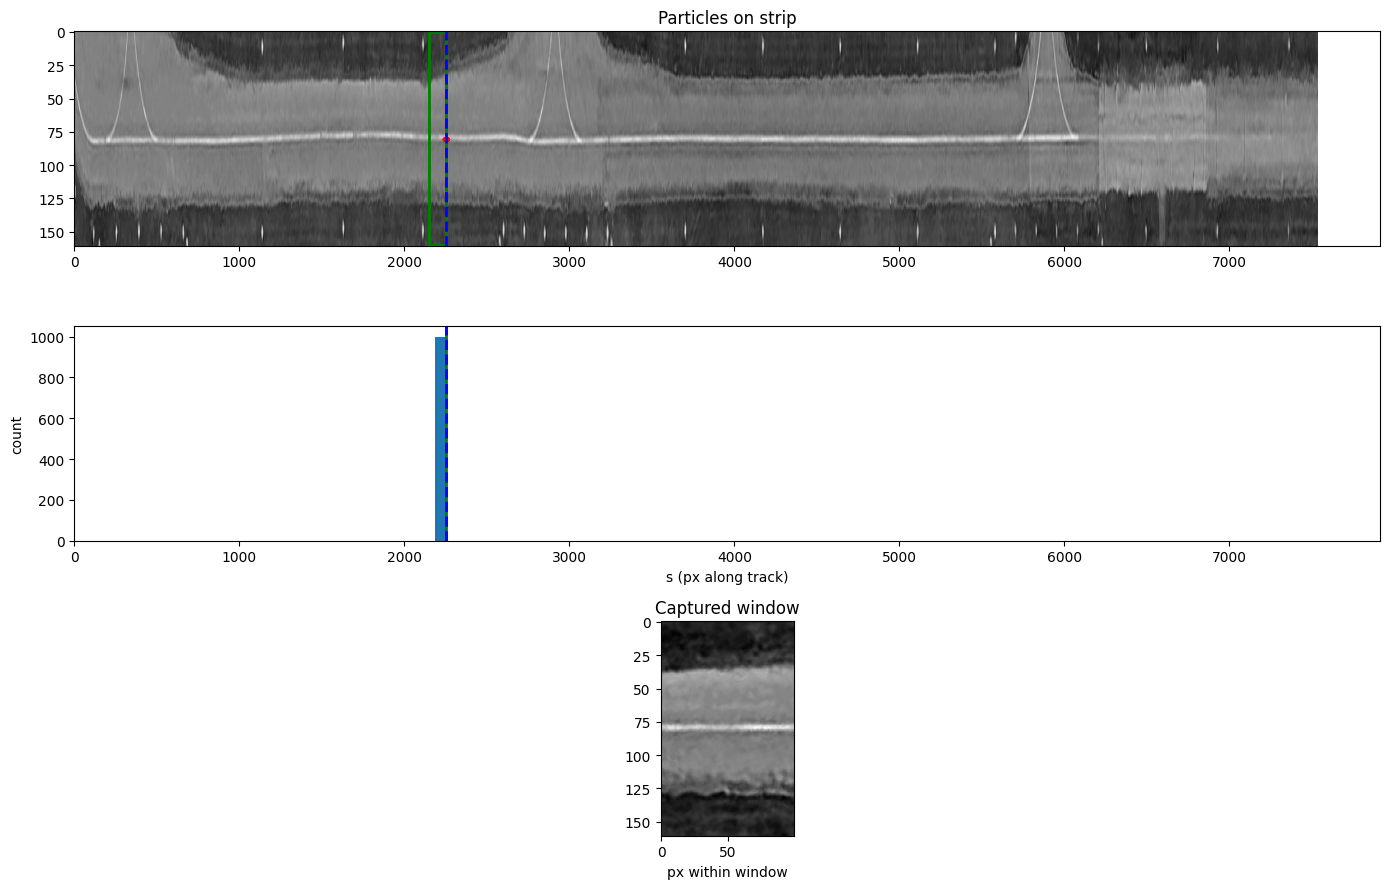

Timestep: 16


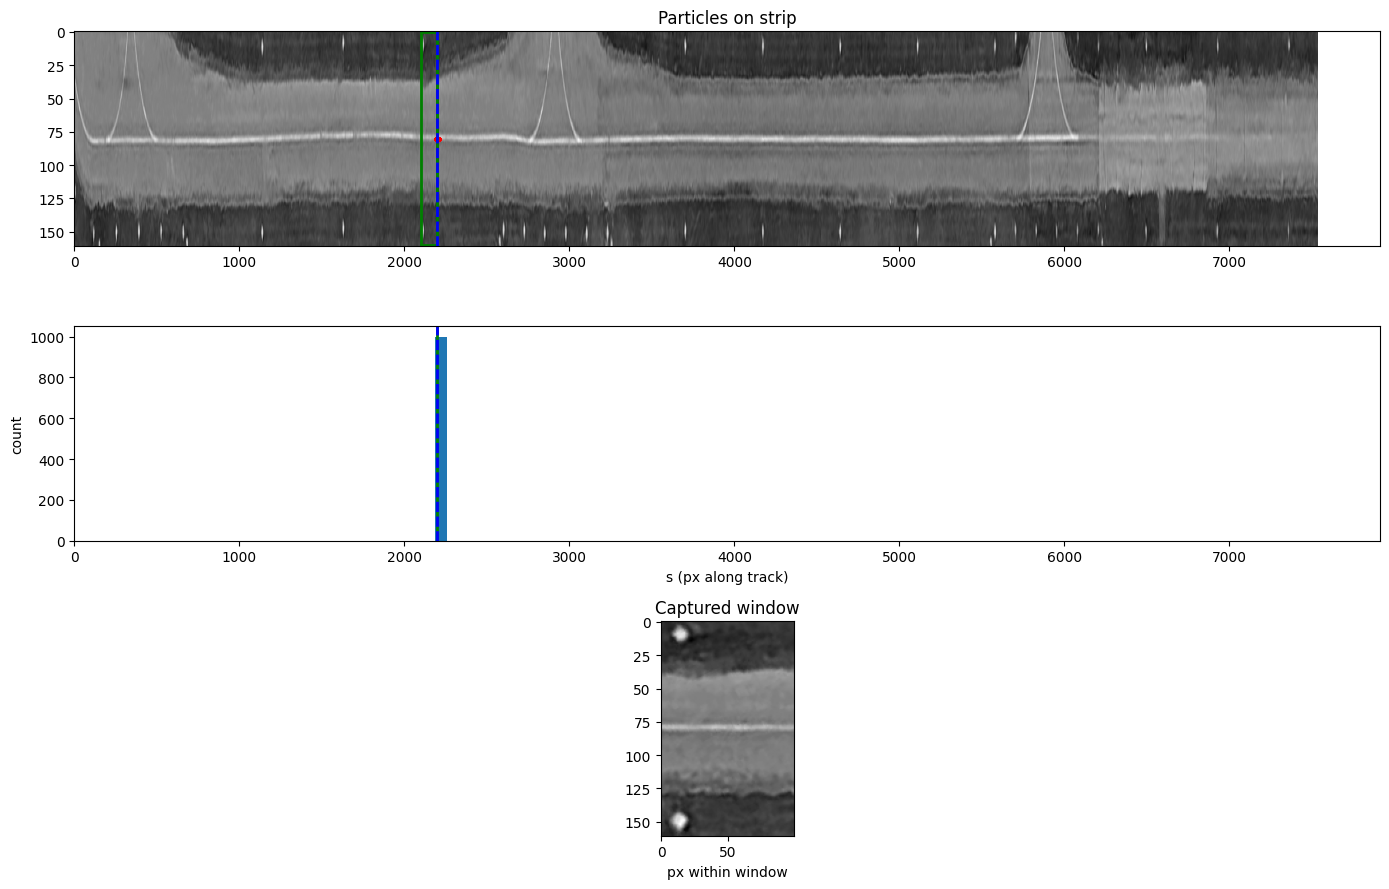

Timestep: 17


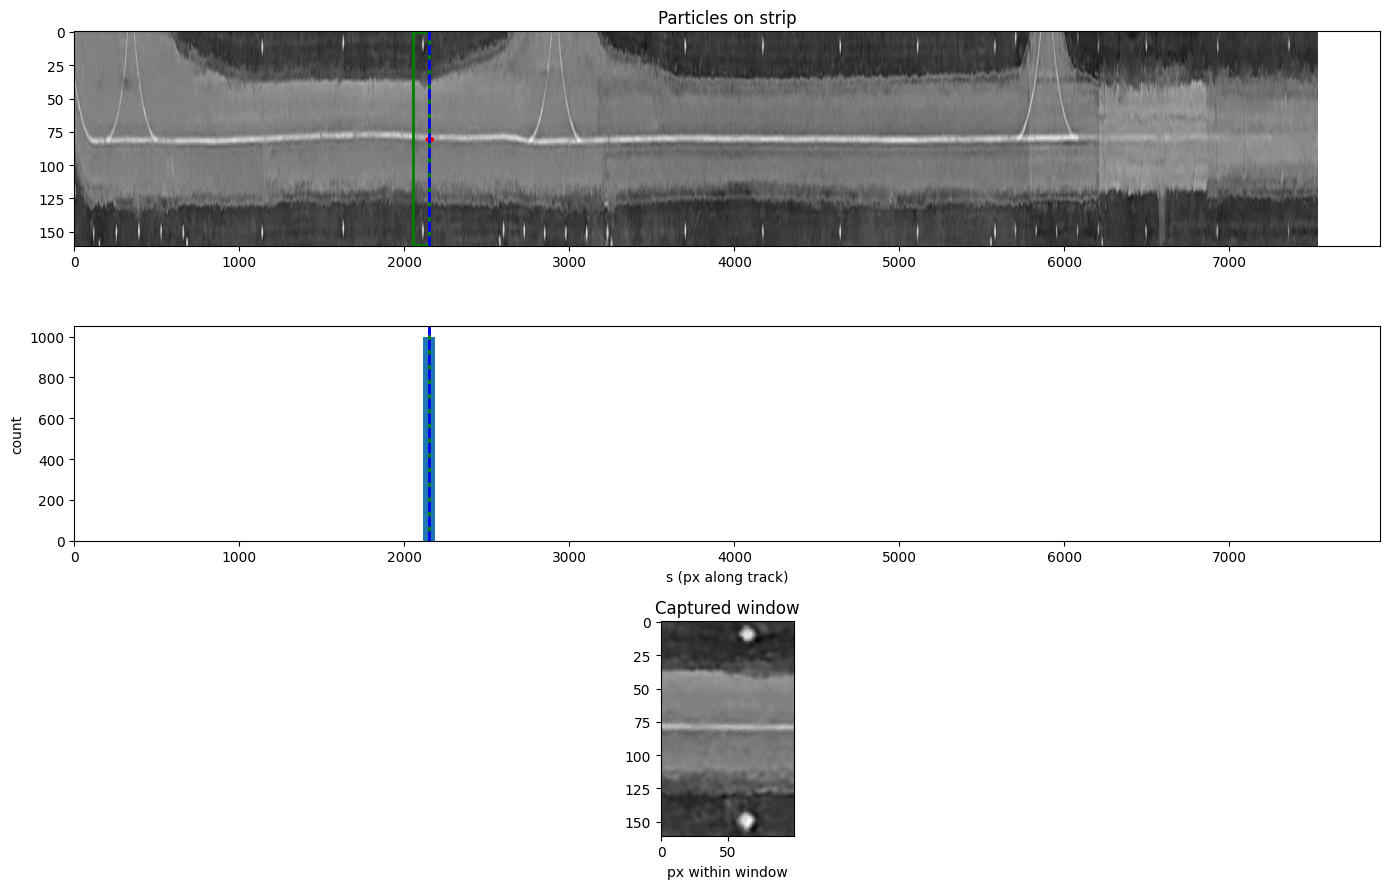

Timestep: 18
RESAMPLE


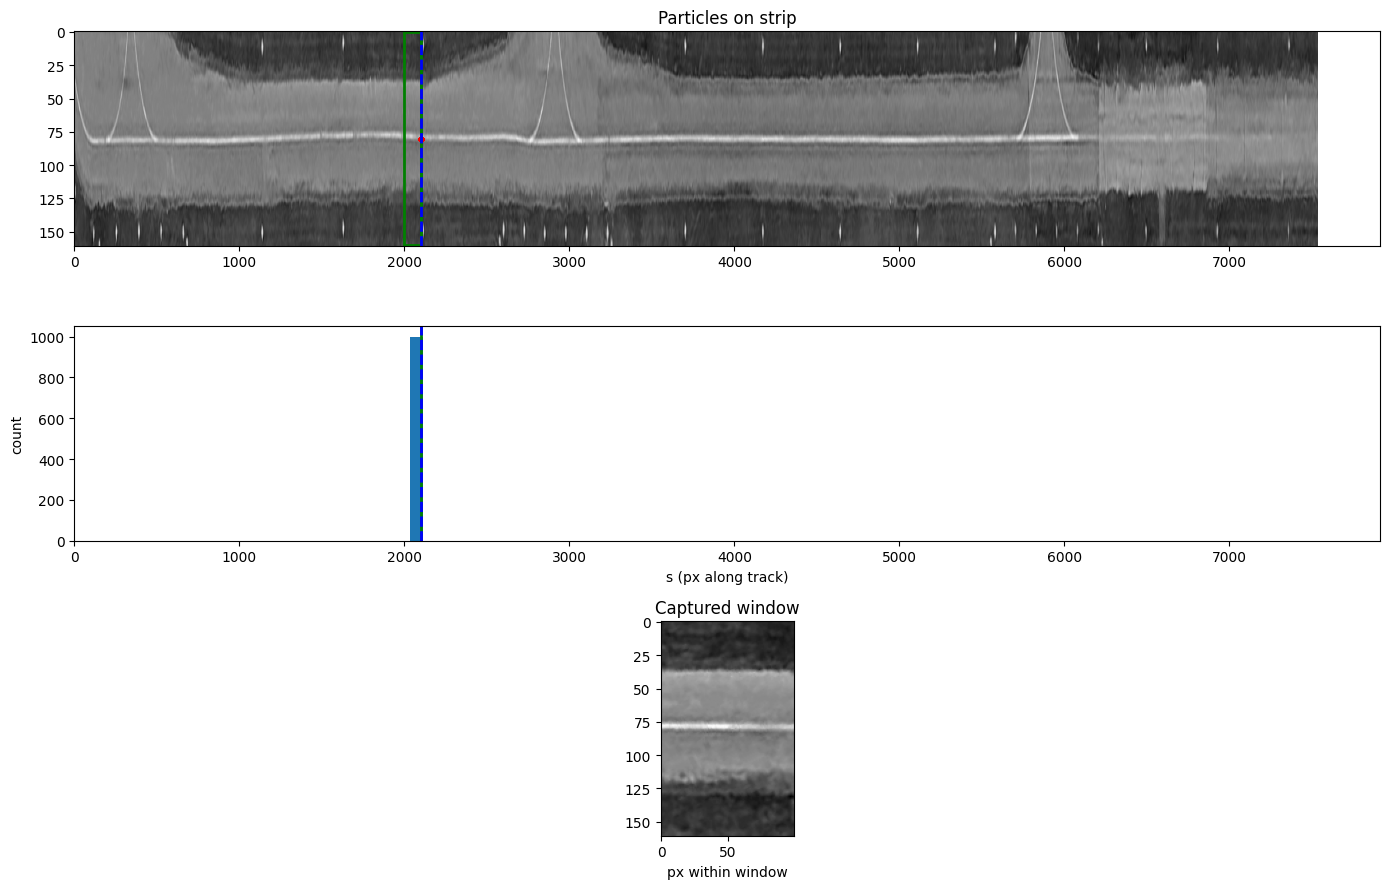

Timestep: 19


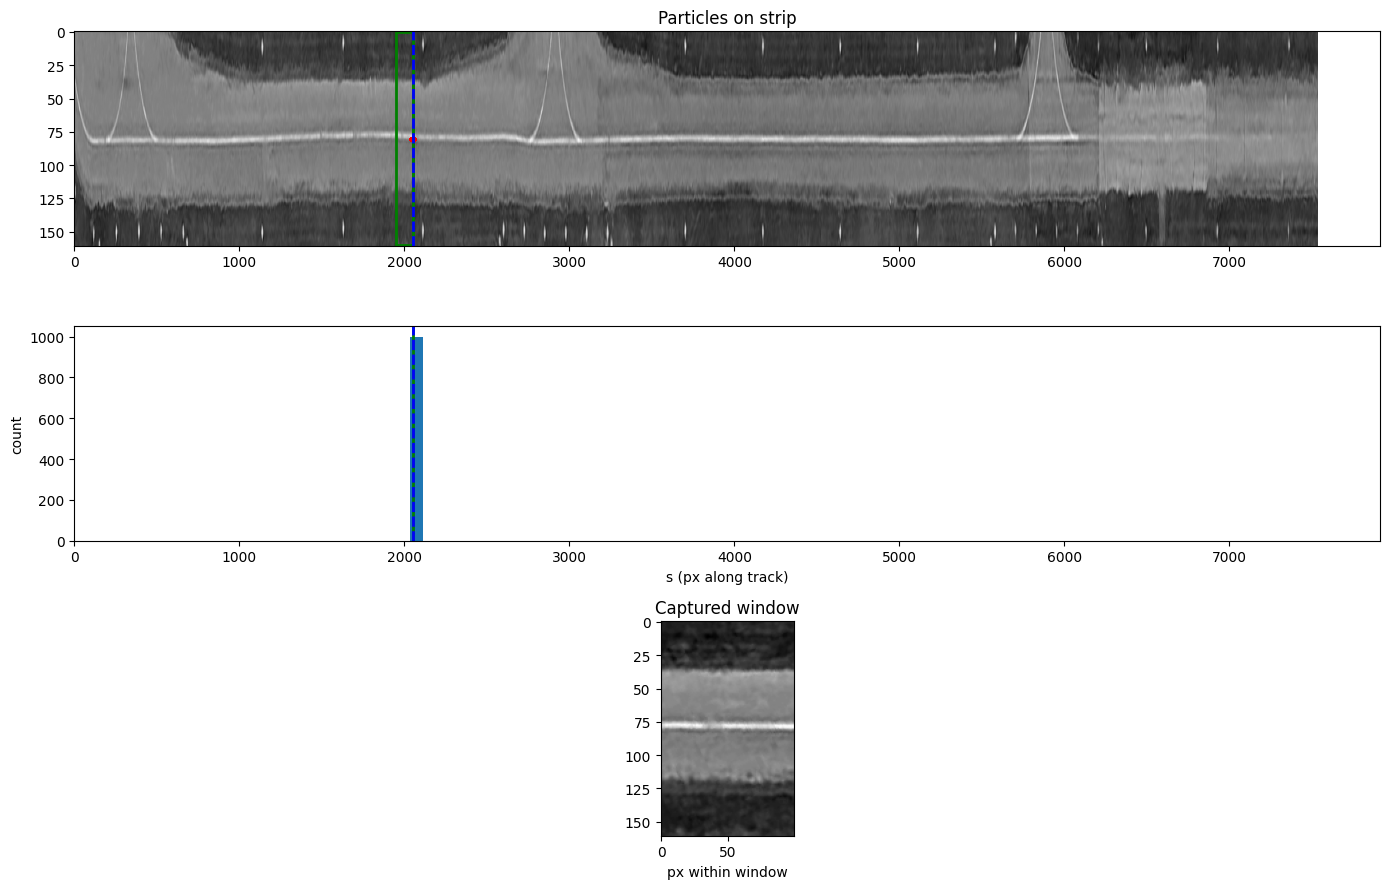

In [6]:
# Re-initialize
pf.init_uniform()
for k in range(K):
    print(f'Timestep: {k}')

    if s_true[k] < pf.s_min:
        break

    if k > 0:
        # Only predict motion motion after movement 
        # V*dt is constant velo motion prediction
        pf.predict(v*dt)
    
    # Capture measurement 
    z = capture(strip, s_true[k], L, heading, sigma_meas=sigma_meas)
    
    # Update particle weights 
    # pf.update(z, sigma_z) # Basic update
    pf.update_st(st_preprocess(z), J_strip, sigma_z_st) # Structure tensor update


    # ADD state estimate
    s_hat = pf.map_estimate(h=5)
    s_grid, p = pf.kde(h=5)

    # Resample 
    if pf.n_eff() < pf.N / 2:
        print("RESAMPLE")
        pf.resample()
    
    # Plot results
    p_near = pf.particles[np.argmin(np.abs(pf.particles - s_true[k] + 200))]
    plot_curr_particles(strip, pf.particles, s_true[k], L=L, s_hat=s_hat, heading=heading, particle_windows=False, z=z) #, p_near=p_near)
    # plot_density(strip, pf, h=5, s_true=s_true[k], s_hat=s_hat)
    
